# Entrega 3 · Correcciones de evaluación (v7)

Complemento autocontenido de `Entrega3_F1_v6.ipynb`. Conserva su preparación,
variables, particiones por carrera y los dos random forest seleccionados. No repite
la búsqueda de familias ni cambia los hiperparámetros: se concentra en la devolución
de `CorreccionesEntrega3.md`. No modifica archivos de la Entrega 4.

**Protocolo fijado antes de ejecutar:** comparar 0,475 (referencia v6), 0,50 y umbrales
inferiores. Elegir el máximo F2 sobre predicciones fuera de fold de 2023–2024 entre
umbrales <= 0,475; desempatar por el mayor umbral. F2 pondera más el recall, pero
se publica su costo en precisión y volumen de alarmas. No se promete una mejora
operativa por cambiar el criterio. 2025 ya fue examinado y es evaluación descriptiva,
no un test virgen. Los puntajes del bosque balanceado no son probabilidades calibradas.

Los folds se reutilizan del trabajo previo: los resultados OOF sirven para elegir
el umbral, no constituyen una estimación independiente del proceso completo de selección.
Las ventanas temporales son retrospectivas y nunca entran como features.

Ejecutar todo desde `Entrega3` con los CSV Silver locales disponibles. Las tablas
y figuras se guardan en `resultados_correcciones/`. Las versiones instaladas se imprimen:
pueden producir diferencias respecto de scikit-learn 1.6.1 usado en la v6.


In [1]:
# ============================================================
# 0. CONFIGURACIÓN, REPRODUCIBILIDAD Y CARGA DE DATOS
# ============================================================
import os, json, time, glob, warnings, urllib.error, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, PredefinedSplit,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
import joblib

SEED = 42
np.random.seed(SEED)
ORDEN = ['SOFT', 'MEDIUM', 'HARD', 'LLUVIA']
CLAVE = ['session_key', 'driver_number', 'lap_number']
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
warnings.filterwarnings('ignore', category=FutureWarning)
print('Versiones -> scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

DIR_DATOS = Path('/content') if Path('/content').is_dir() else Path.cwd()
FILAS_ESPERADAS = {'f1_silver_dataset': 77373, 'f1_silver_pit_stops': 2333}
COLUMNAS_ESPERADAS = {'f1_silver_dataset': 89, 'f1_silver_pit_stops': 93}

# Si los CSV no se subieron a Colab, se obtienen igual que en la Entrega 2:
# vueltas desde el Drive del grupo y paradas reconstruidas desde OpenF1 con la lógica del pipeline.
ID_DRIVE_VUELTAS = '1ehu7TcvLSt25rHI7lYz5O9IlQ17faG_N'
ID_DRIVE_PITS = ''   # completar si se sube a Drive el f1_silver_pit_stops.csv de la corrida de Airflow


def buscar_csv(stem):
    candidatos = set()
    for d in [DIR_DATOS, Path('/mnt/data'), Path('include/output/silver'), Path('../include/output/silver')]:
        if d.exists():
            candidatos.update(d.glob(stem + '*.csv'))
    validos = []
    for archivo in sorted(candidatos):
        try:
            tabla = pd.read_csv(archivo, low_memory=False)
        except Exception as e:
            print(f'  Error leyendo {archivo.name}: {e}')
            continue
        print(f'  {archivo.name}: {tabla.shape[0]} filas, {tabla.shape[1]} columnas')
        if tabla.shape == (FILAS_ESPERADAS[stem], COLUMNAS_ESPERADAS[stem]):
            validos.append((archivo, tabla))
    if not validos:
        return None, None
    return max(validos, key=lambda item: item[0].stat().st_mtime)


def bajar_de_drive(id_drive, destino):
    import gdown
    gdown.download(id=id_drive, output=str(destino), quiet=True)

Versiones -> scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


In [2]:
# Respaldo para el CSV de paradas: copia de la reconstrucción usada en la Entrega 2
# (resolve_driver_pits es la misma función de src/silver_pipeline.py del pipeline de la Entrega 1).
def resolve_driver_pits(driver_pits, driver_stints):
    pits_sorted = sorted(driver_pits, key=lambda p: (p.get("lap_number") or 0, p.get("date") or ""))
    stints_sorted = sorted(driver_stints, key=lambda s: (s.get("stint_number") or 0, s.get("lap_start") or 0))
    details_by_lap = {}
    for pit_idx, p in enumerate(pits_sorted):
        p_lap = p.get("lap_number")
        if p_lap is None:
            continue
        stint_in = None
        stint_out = None
        if len(stints_sorted) == len(pits_sorted) + 1:
            stint_in = stints_sorted[pit_idx]
            stint_out = stints_sorted[pit_idx + 1]
        else:
            candidates_out = [
                s for s in stints_sorted
                if (s.get("lap_start") or 0) > p_lap
                or ((s.get("lap_start") or 0) == p_lap and (s.get("stint_number") or 0) > 1)
            ]
            if candidates_out:
                stint_out = candidates_out[0]
                out_idx = stints_sorted.index(stint_out)
                if out_idx > 0:
                    stint_in = stints_sorted[out_idx - 1]
            else:
                stint_in = stints_sorted[-1] if stints_sorted else None
                stint_out = None
        details_by_lap[p_lap] = {
            "pit_stop_number": pit_idx + 1,
            "stint_in_number": stint_in.get("stint_number") if stint_in else None,
            "current_compound": stint_in.get("compound") if stint_in else None,
            "tyre_age_at_start": stint_in.get("tyre_age_at_start") if stint_in else None,
            "new_stint_number": stint_out.get("stint_number") if stint_out else None,
            "new_compound": stint_out.get("compound") if stint_out else None,
            "new_tyre_age_at_start": stint_out.get("tyre_age_at_start") if stint_out else None,
        }
    return details_by_lap


def bajar_openf1(endpoint, session_key, carpeta="bronze_openf1"):
    os.makedirs(carpeta, exist_ok=True)
    ruta = f"{carpeta}/{endpoint}_{session_key}.json"
    if os.path.exists(ruta):
        with open(ruta) as f:
            return json.load(f)
    url = f"https://api.openf1.org/v1/{endpoint}?session_key={session_key}"
    for intento in range(6):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                datos = json.loads(r.read())
            break
        except urllib.error.HTTPError as e:
            if e.code == 404:
                datos = []
                break
            time.sleep(2 ** intento)
        except OSError:
            time.sleep(2 ** intento)
    else:
        raise RuntimeError(f"No se pudo descargar {url}")
    with open(ruta, "w") as f:
        json.dump(datos, f)
    time.sleep(0.5)
    return datos


def reconstruir_pits_desde_openf1(df_vueltas):
    vueltas_idx = {(r["session_key"], r["driver_number"], r["lap_number"]): r
                   for r in df_vueltas.to_dict("records")}
    carreras = sorted(df_vueltas.loc[df_vueltas["pit_data_available"] == True, "session_key"].unique())
    salida = []
    for sk in carreras:
        pits_por_piloto, stints_por_piloto = {}, {}
        for p in bajar_openf1("pit", sk):
            pits_por_piloto.setdefault(p["driver_number"], []).append(p)
        for s in bajar_openf1("stints", sk):
            stints_por_piloto.setdefault(s["driver_number"], []).append(s)
        for piloto, pits_piloto in pits_por_piloto.items():
            detalle = resolve_driver_pits(pits_piloto, stints_por_piloto.get(piloto, []))
            for vuelta, det in detalle.items():
                clave = (sk, piloto, vuelta)
                if clave not in vueltas_idx:
                    continue
                fila = dict(vueltas_idx[clave])
                fila["pit_stop_number"] = det["pit_stop_number"]
                for col_det, col_fila in [("current_compound", "current_compound"),
                                          ("stint_in_number", "stint_number"),
                                          ("tyre_age_at_start", "tyre_age_at_start")]:
                    if det[col_det] is not None:
                        fila[col_fila] = det[col_det]
                fila["new_stint_number"] = det["new_stint_number"]
                fila["new_compound"] = det["new_compound"]
                fila["new_tyre_age_at_start"] = det["new_tyre_age_at_start"]
                fila["pit_stop"] = True
                salida.append(fila)
    if not salida:
        raise RuntimeError("OpenF1 no devolvió paradas: revisar la conexión o volver a correr más tarde.")
    return pd.DataFrame(salida).drop_duplicates(["session_key", "driver_number", "lap_number"], keep="last")

In [3]:
print('Buscando f1_silver_dataset')
f_vueltas, raw = buscar_csv('f1_silver_dataset')
if raw is None:
    print('  No está en el entorno: se baja del Drive del grupo (mismo archivo que la Entrega 2).')
    bajar_de_drive(ID_DRIVE_VUELTAS, DIR_DATOS / 'f1_silver_dataset.csv')
    f_vueltas, raw = buscar_csv('f1_silver_dataset')
assert raw is not None, 'No se pudo obtener f1_silver_dataset.csv'

print('Buscando f1_silver_pit_stops')
f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
if raw_pits is None and ID_DRIVE_PITS:
    bajar_de_drive(ID_DRIVE_PITS, DIR_DATOS / 'f1_silver_pit_stops.csv')
    f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
if raw_pits is None:
    print('  No está en el entorno: se reconstruye desde OpenF1 con la lógica del pipeline (≈2 min).')
    reconstruir_pits_desde_openf1(raw).to_csv(DIR_DATOS / 'f1_silver_pit_stops_reconstruido.csv', index=False)
    f_pits, raw_pits = buscar_csv('f1_silver_pit_stops')
assert raw_pits is not None, 'No se pudo obtener el CSV de paradas'
print('\nARCHIVOS USADOS:', f_vueltas.name, '|', f_pits.name)

assert set(CLAVE).issubset(raw.columns) and set(CLAVE).issubset(raw_pits.columns)
assert raw.duplicated(CLAVE).sum() == 0, 'Existen vueltas duplicadas.'
assert raw_pits.duplicated(CLAVE).sum() == 0, 'Existen paradas duplicadas.'
assert set(raw_pits.session_key.dropna()).issubset(set(raw.session_key.dropna()))
print('Validaciones de integridad superadas. Vueltas:', raw.shape, '| Paradas:', raw_pits.shape)
display(raw.groupby('season').agg(vueltas=('lap_number', 'size'), carreras=('session_key', 'nunique'))
        .join(raw_pits.groupby('season').agg(paradas=('lap_number', 'size'),
                                             carreras_con_paradas=('session_key', 'nunique'))))

Buscando f1_silver_dataset


  f1_silver_dataset.csv: 77373 filas, 89 columnas
Buscando f1_silver_pit_stops
  f1_silver_pit_stops.csv: 2333 filas, 93 columnas

ARCHIVOS USADOS: f1_silver_dataset.csv | f1_silver_pit_stops.csv
Validaciones de integridad superadas. Vueltas: (77373, 89) | Paradas: (2333, 93)


,vueltas,carreras,paradas,carreras_con_paradas
season,,,,
2023,24479,22,693,16
2024,26629,24,825,24
2025,26265,24,815,24


In [4]:
# Conservar solo carreras con objetivo observable; NO imputar pit_stop nulo como False.
vueltas = raw.loc[raw['pit_stop'].notna()].copy()
vueltas['pit_stop'] = vueltas['pit_stop'].astype(str).str.lower().eq('true') | (vueltas['pit_stop'] == 1)
vueltas['season'] = pd.to_numeric(vueltas['season'], errors='raise').astype(int)
vueltas = vueltas.sort_values(CLAVE).reset_index(drop=True)

# Corrección acotada de inconsistencia de origen: Bélgica 2025, stint 2 sin parada previa.
# El detector usa SOLO historia de neumáticos y paradas, nunca el compuesto que se intenta predecir.
stints = (vueltas.groupby(['session_key','driver_number','stint_number'], dropna=False)
          .agg(primera=('lap_number','min'),ultima=('lap_number','max'),compuesto=('current_compound','first')).reset_index())
s1 = stints[(stints.stint_number == 1)&(stints.ultima == 1)]
s2 = stints[(stints.stint_number == 2)&(stints.primera == 2)]
candidatos = s1.merge(s2, on=['session_key','driver_number'],suffixes=('_1','_2'))
paradas_1_2 = (vueltas.loc[vueltas.pit_stop & vueltas.lap_number.le(2)]
               .groupby(['session_key','driver_number']).size())
candidatos['parada_temprana'] = candidatos.set_index(['session_key','driver_number']).index.map(paradas_1_2).fillna(0)
corregir = candidatos.loc[candidatos.compuesto_1.ne(candidatos.compuesto_2) & candidatos.parada_temprana.eq(0),
                          ['session_key','driver_number','compuesto_1']].copy()
if len(corregir):
    clave_corr = corregir.set_index(['session_key','driver_number'])['compuesto_1']
    idx = pd.MultiIndex.from_frame(vueltas[['session_key','driver_number']])
    previo = pd.Series(idx.map(clave_corr), index=vueltas.index)
    mask = previo.notna() & vueltas.stint_number.eq(2)
    vueltas.loc[mask,'current_compound'] = previo[mask]
    # No se reajusta tyre_age sin evidencia del registro exacto de edad.
print('Pilotos con inconsistencia de stint detectada:',len(corregir))
print('Vueltas sin etiqueta descartadas:',raw.pit_stop.isna().sum())
print('Vueltas válidas:',len(vueltas),'| Paradas reales:',int(vueltas.pit_stop.sum()))
assert set(vueltas.season.unique()) >= {2023,2024,2025}

Pilotos con inconsistencia de stint detectada: 20
Vueltas sin etiqueta descartadas: 6627
Vueltas válidas: 70746 | Paradas reales: 2333


In [5]:
# Variables que entran a los modelos (todas se calculan DENTRO del pipeline, en el paso HistoriaCausal).
NUM = ['lap_number', 'tyre_age_prev', 'position_prev', 'stops_before', 'track_temperature_prev',
       'air_temperature_prev', 'humidity_prev', 'used_soft', 'used_medium', 'used_hard',
       'field_soft_prev', 'field_medium_prev', 'field_hard_prev', 'field_lluvia_prev']
CAT = ['compound_prev', 'circuit_short_name', 'team_name', 'rainfall_prev']
FEATURES = NUM + CAT
PROHIBIDAS = {'pit_stop', 'new_compound', 'current_compound', 'stint_number', 'pit_duration',
              'lane_duration', 'stop_duration', 'session_max_lap_observed', 'lap_duration',
              'gap_to_leader_raw', 'safety_car_active', 'yellow_flag_active', 'interval_raw'}
assert not (set(FEATURES) & PROHIBIDAS)
# Lo único que recibe el pipeline por cada vuelta a decidir: quién, dónde y en qué vuelta.
COLS_X = CLAVE + ['circuit_short_name', 'team_name']
COMPUESTOS_SECO = ['SOFT', 'MEDIUM', 'HARD']


class RegistroCarreras:
    """Registro de vueltas por carrera, como lo tendría la app durante la carrera.

    Guarda el estado ya calculado de cada carrera para no recalcularlo en cada fold.
    Al clonar el pipeline se comparte el mismo registro (no se copia).
    """
    COLUMNAS = ['session_key', 'driver_number', 'lap_number', 'pit_stop', 'current_compound',
                'tyre_age', 'position', 'rainfall', 'track_temperature', 'air_temperature', 'humidity']

    def __init__(self, vueltas):
        self.vueltas = vueltas[self.COLUMNAS].sort_values(CLAVE).reset_index(drop=True)
        self._piloto, self._peloton = {}, {}

    def __deepcopy__(self, memo):
        return self

    def estado(self, carreras):
        faltan = [c for c in pd.unique(carreras) if c not in self._piloto]
        if faltan:
            v = self.vueltas[self.vueltas.session_key.isin(faltan)].copy()
            gp = v.groupby(['session_key', 'driver_number'], sort=False)
            # Estado del piloto AL TERMINAR cada vuelta; se usa recién en una vuelta posterior.
            piloto = v[CLAVE].copy()
            for col, nueva in {'current_compound': 'compound_prev', 'tyre_age': 'tyre_age_prev',
                               'position': 'position_prev', 'rainfall': 'rainfall_prev',
                               'track_temperature': 'track_temperature_prev',
                               'air_temperature': 'air_temperature_prev', 'humidity': 'humidity_prev'}.items():
                piloto[nueva] = v[col]
            piloto['stops_before'] = gp['pit_stop'].cumsum().astype(int)
            for c in COMPUESTOS_SECO:
                piloto[f'used_{c.lower()}'] = (v.current_compound.eq(c).astype(float)
                                               .groupby([v.session_key, v.driver_number]).cummax())
            # Proporción del pelotón en cada compuesto al terminar cada vuelta.
            frac = pd.crosstab([v.session_key, v.lap_number], v.current_compound, normalize='index')
            for c in COMPUESTOS_SECO + ['INTERMEDIATE', 'WET']:
                if c not in frac.columns:
                    frac[c] = 0.0
            frac['LLUVIA'] = frac['INTERMEDIATE'] + frac['WET']
            frac = (frac[COMPUESTOS_SECO + ['LLUVIA']]
                    .rename(columns=lambda c: f'field_{c.lower()}_prev').reset_index())
            for c in faltan:
                self._piloto[c] = piloto[piloto.session_key.eq(c)]
                self._peloton[c] = frac[frac.session_key.eq(c)]
        lista = list(pd.unique(carreras))
        return (pd.concat([self._piloto[c] for c in lista], ignore_index=True),
                pd.concat([self._peloton[c] for c in lista], ignore_index=True))


class HistoriaCausal(BaseEstimator, TransformerMixin):
    """Primer paso del pipeline: arma las variables históricas de cada vuelta a decidir.

    Del registro lee SOLO vueltas anteriores de la misma carrera: la última vuelta previa
    del piloto y la vuelta t-1 del pelotón. fit no aprende nada (no hay estadísticas del dataset).
    """

    def __init__(self, registro=None):
        self.registro = registro

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        piloto, peloton = self.registro.estado(X['session_key'])
        base = X[COLS_X].copy()
        base['_orden'] = np.arange(len(base))
        base['lap_number'] = base['lap_number'].astype('int64')
        piloto = piloto.astype({'lap_number': 'int64'}).sort_values('lap_number')
        # allow_exact_matches=False: la última vuelta del piloto ESTRICTAMENTE anterior a la que se decide.
        salida = pd.merge_asof(base.sort_values('lap_number'), piloto, on='lap_number',
                               by=['session_key', 'driver_number'],
                               allow_exact_matches=False, direction='backward')
        peloton = peloton.assign(lap_number=peloton.lap_number.astype('int64') + 1)
        salida = salida.merge(peloton, on=['session_key', 'lap_number'], how='left')
        salida = salida.sort_values('_orden').reset_index(drop=True)
        salida['stops_before'] = salida['stops_before'].fillna(0)
        for c in COMPUESTOS_SECO:
            salida[f'used_{c.lower()}'] = salida[f'used_{c.lower()}'].fillna(0.0)
        salida.index = X.index
        return salida[FEATURES]


REGISTRO = RegistroCarreras(vueltas)

# Población: vueltas con al menos una vuelta previa del piloto con compuesto y edad conocidos.
# Es la definición de qué filas se predicen (no una estadística): mira una sola fila hacia atrás.
gpv = vueltas.groupby(['session_key', 'driver_number'], sort=False)
tiene_historia = gpv['current_compound'].shift(1).notna() & gpv['tyre_age'].shift(1).notna()
DESCRIPTIVAS = ['season', 'meeting_name', 'full_name', 'pit_stop', 'safety_car_active']
poblacion = vueltas.loc[tiene_historia, COLS_X + DESCRIPTIVAS].reset_index(drop=True)

objetivos = raw_pits[CLAVE + ['new_compound']].copy()
objetivos['objetivo_compuesto'] = objetivos['new_compound'].replace({'INTERMEDIATE': 'LLUVIA', 'WET': 'LLUVIA'})
poblacion = poblacion.merge(objetivos[CLAVE + ['objetivo_compuesto']], on=CLAVE, how='left', validate='one_to_one')
assert poblacion.loc[poblacion.pit_stop, 'objetivo_compuesto'].isin(ORDEN).all(), 'Paradas sin compuesto.'
print('Observaciones con historia:', len(poblacion), '| Paradas con compuesto:', int(poblacion.pit_stop.sum()))
display(poblacion.groupby('season').agg(vueltas=('pit_stop', 'size'), paradas=('pit_stop', 'sum'),
                                        carreras=('session_key', 'nunique')))
display(poblacion.loc[poblacion.pit_stop, 'objetivo_compuesto'].value_counts().reindex(ORDEN).to_frame('paradas'))

Observaciones con historia: 69472 | Paradas con compuesto: 2244


,vueltas,paradas,carreras
season,,,
2023,17534,657,16
2024,26151,785,24
2025,25787,802,24


,paradas
objetivo_compuesto,
SOFT,321
MEDIUM,631
HARD,1072
LLUVIA,220


In [6]:
# Chequeo de fuga temporal del paso HistoriaCausal.
# 1) Se calculan las variables de todas las vueltas (solo para describir; el modelo las recalcula adentro).
estado = HistoriaCausal(REGISTRO).fit_transform(poblacion[COLS_X])
descr = pd.concat([poblacion, estado.drop(columns=['lap_number', 'circuit_short_name', 'team_name'])], axis=1)

# 2) Prueba de "borrar el futuro": para 300 vueltas al azar se borra del registro TODO lo que pasó
#    desde esa vuelta en adelante (todos los pilotos). Si alguna variable usara el futuro, cambiaría.
muestra = poblacion.sample(300, random_state=SEED)
cambios = 0
for i, fila in muestra.iterrows():
    sin_futuro = vueltas[~(vueltas.session_key.eq(fila.session_key) & vueltas.lap_number.ge(fila.lap_number))]
    recalculado = HistoriaCausal(RegistroCarreras(sin_futuro)).transform(muestra.loc[[i], COLS_X])
    cambios += int(not recalculado.astype(str).equals(estado.loc[[i]].astype(str)))
print(f'Vueltas cuyo vector de variables cambia al borrar el futuro: {cambios} de {len(muestra)}')
assert cambios == 0


# 3) Mismas variables que la v5: se compara contra construir_historia, que en la v5 corría afuera del pipeline.
def construir_historia_v5(tabla):
    v = tabla.sort_values(CLAVE).copy()
    gp = v.groupby(['session_key', 'driver_number'], sort=False)
    for col, nueva in {'current_compound': 'compound_prev', 'tyre_age': 'tyre_age_prev', 'position': 'position_prev',
                       'rainfall': 'rainfall_prev', 'track_temperature': 'track_temperature_prev',
                       'air_temperature': 'air_temperature_prev', 'humidity': 'humidity_prev'}.items():
        v[nueva] = gp[col].shift(1)
    v['stops_before'] = gp['pit_stop'].cumsum().astype(int) - v['pit_stop'].astype(int)
    for compuesto in COMPUESTOS_SECO:
        usado = v.current_compound.eq(compuesto).astype(float)
        v[f'used_{compuesto.lower()}'] = usado.groupby([v.session_key, v.driver_number]).transform(lambda s: s.shift(1).cummax())
    frac = pd.crosstab([v.session_key, v.lap_number], v.current_compound, normalize='index')
    for c in COMPUESTOS_SECO + ['INTERMEDIATE', 'WET']:
        if c not in frac.columns:
            frac[c] = 0.0
    frac['LLUVIA'] = frac['INTERMEDIATE'] + frac['WET']
    frac = frac[COMPUESTOS_SECO + ['LLUVIA']].rename(columns=lambda c: f'field_{c.lower()}_prev').reset_index()
    frac.lap_number += 1
    return v.merge(frac, on=['session_key', 'lap_number'], how='left', validate='many_to_one')


v5h = poblacion[CLAVE].merge(construir_historia_v5(vueltas), on=CLAVE, how='left')
distintas = [c for c in FEATURES if not (
    np.allclose(pd.to_numeric(v5h[c]).fillna(-999), pd.to_numeric(estado[c]).fillna(-999)) if c in NUM
    else v5h[c].astype(str).equals(estado[c].astype(str)))]
print('Variables distintas de las de la v5:', distintas or 'ninguna')
assert not distintas
print('Columnas que el pipeline recibe por vuelta:', COLS_X)
print('Columnas del registro que puede leer (solo vueltas anteriores):', RegistroCarreras.COLUMNAS)

Vueltas cuyo vector de variables cambia al borrar el futuro: 0 de 300


Variables distintas de las de la v5: ninguna
Columnas que el pipeline recibe por vuelta: ['session_key', 'driver_number', 'lap_number', 'circuit_short_name', 'team_name']
Columnas del registro que puede leer (solo vueltas anteriores): ['session_key', 'driver_number', 'lap_number', 'pit_stop', 'current_compound', 'tyre_age', 'position', 'rainfall', 'track_temperature', 'air_temperature', 'humidity']


In [7]:
train = poblacion[poblacion.season.lt(2025)].reset_index(drop=True)
test = poblacion[poblacion.season.eq(2025)].reset_index(drop=True)
assert set(train.session_key).isdisjoint(set(test.session_key))


def pipeline(modelo, nums=NUM, cats=CAT):
    preparar = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), list(nums)),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), list(cats))])
    return Pipeline([('historia', HistoriaCausal(REGISTRO)), ('preparar', preparar), ('modelo', modelo)])


def split_datos(tabla, solo_pits=False):
    v = tabla.loc[tabla.pit_stop].reset_index(drop=True) if solo_pits else tabla
    y = v.objetivo_compuesto if solo_pits else v.pit_stop.astype(int)
    return v[COLS_X].copy(), y, v.session_key


Xpit, ypit, gpit = split_datos(train)
Xpit_test, ypit_test, _ = split_datos(test)
Xcomp, ycomp, gcomp = split_datos(train, True)
Xcomp_test, ycomp_test, _ = split_datos(test, True)
print('Entrenamiento 2023-2024:', len(Xpit), 'vueltas,', int(ypit.sum()), 'paradas,', gpit.nunique(), 'carreras')
print('Test 2025:', len(Xpit_test), 'vueltas,', int(ypit_test.sum()), 'paradas,', test.session_key.nunique(), 'carreras')

Entrenamiento 2023-2024: 43685 vueltas, 1442 paradas, 40 carreras
Test 2025: 25787 vueltas, 802 paradas, 24 carreras


In [8]:
# Corrección: se reparten CARRERAS (no filas) en 4 pedazos, estratificando las carreras por "tuvo lluvia".
# Con 4 carreras con lluvia en 2023-2024, 4 pedazos es el máximo que deja una carrera con lluvia en cada uno.
# Toda carrera cae entera de un solo lado, igual que con StratifiedGroupKFold.
N_FOLDS = 4
carreras_train = (train.groupby('session_key')
                  .agg(lluvia=('objetivo_compuesto', lambda s: s.eq('LLUVIA').any()),
                       meeting_name=('meeting_name', 'first'), season=('season', 'first')).reset_index())


def folds_por_carrera(seed=SEED):
    asignacion = pd.Series(-1, index=carreras_train.session_key)
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for i, (_, b) in enumerate(skf.split(carreras_train, carreras_train.lluvia)):
        asignacion.iloc[b] = i
    return asignacion


def cv_por_carrera(grupos, seed=SEED):
    return PredefinedSplit(grupos.map(folds_por_carrera(seed)).values)


cvpit, cvcomp = cv_por_carrera(gpit), cv_por_carrera(gcomp)


def auditar_folds(y, gr, cv):
    filas = []
    for i, (a, b) in enumerate(cv.split(), 1):
        assert set(gr.iloc[a]).isdisjoint(set(gr.iloc[b]))
        fila = {'fold': i, 'filas_validacion': len(b), 'carreras_validacion': gr.iloc[b].nunique(),
                'carreras_compartidas': 0}
        fila.update({f'clase_{k}': int(v) for k, v in y.iloc[b].value_counts().items()})
        filas.append(fila)
    return pd.DataFrame(filas).fillna(0).set_index('fold')


print('PIT STOP:'); display(auditar_folds(ypit, gpit, cvpit))
print('COMPUESTO:'); display(auditar_folds(ycomp, gcomp, cvcomp)[['filas_validacion', 'carreras_validacion'] + [f'clase_{k}' for k in ORDEN]])
print('Carreras con lluvia por fold:', carreras_train.assign(fold=folds_por_carrera().values)
      .loc[lambda d: d.lluvia].set_index('fold').meeting_name.sort_index().to_dict())

PIT STOP:


,filas_validacion,carreras_validacion,carreras_compartidas,clase_0,clase_1
fold,,,,,
1,11074,10,0,10662,412
2,10921,10,0,10591,330
3,10221,10,0,9904,317
4,11469,10,0,11086,383


COMPUESTO:


,filas_validacion,carreras_validacion,clase_SOFT,clase_MEDIUM,clase_HARD,clase_LLUVIA
fold,,,,,,
1,412,10,85,92,178,57
2,330,10,14,55,226,35
3,317,10,31,83,180,23
4,383,10,58,131,175,19


Carreras con lluvia por fold: {0: 'Dutch Grand Prix', 1: 'São Paulo Grand Prix', 2: 'British Grand Prix', 3: 'Canadian Grand Prix'}


In [9]:
"""Evaluación descriptiva de alarmas, sin modificar etiquetas ni entrenar modelos."""
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, fbeta_score

CLAVES_EVALUACION = ['session_key', 'driver_number', 'lap_number']


def auditar_alarmas(datos, probabilidades, umbral):
    tabla = datos.copy().reset_index(drop=True)
    if tabla.duplicated(CLAVES_EVALUACION).any():
        raise ValueError('La evaluación exige una fila por piloto, carrera y vuelta')
    if tabla.pit_stop.isna().any():
        raise ValueError('No se pueden evaluar etiquetas ausentes')
    p = np.asarray(probabilidades, dtype=float)
    if len(p) != len(tabla) or not np.isfinite(p).all():
        raise ValueError('Puntajes ausentes o desalineados')
    tabla['puntaje'] = p
    tabla['alarma'] = p >= umbral
    tabla['real'] = tabla.pit_stop.astype(bool)
    tabla['distancia_proxima_parada'] = np.nan
    tabla['desde_parada_anterior'] = np.nan
    tabla['vueltas_observadas_restantes'] = 0
    for _, g in tabla.groupby(['session_key', 'driver_number']):
        laps = g.lap_number.to_numpy()
        pits = np.sort(g.loc[g.real, 'lap_number'].to_numpy())
        tabla.loc[g.index, 'vueltas_observadas_restantes'] = laps.max() - laps
        if len(pits):
            siguiente = np.searchsorted(pits, laps, side='right')
            anterior = np.searchsorted(pits, laps, side='left') - 1
            dprox = np.full(len(g), np.nan)
            dprev = np.full(len(g), np.nan)
            hay_proxima, hay_anterior = siguiente < len(pits), anterior >= 0
            dprox[hay_proxima] = pits[siguiente[hay_proxima]] - laps[hay_proxima]
            dprev[hay_anterior] = laps[hay_anterior] - pits[anterior[hay_anterior]]
            tabla.loc[g.index, 'distancia_proxima_parada'] = dprox
            tabla.loc[g.index, 'desde_parada_anterior'] = dprev
    tabla['tipo'] = np.select([tabla.real & tabla.alarma, ~tabla.real & tabla.alarma,
                               tabla.real & ~tabla.alarma], ['VP', 'FP', 'FN'], default='VN')
    d = tabla.distancia_proxima_parada
    tabla['categoria_fp'] = np.select(
        [tabla.tipo.ne('FP'), d.eq(1), d.between(2, 3), d.between(4, 10), d.gt(10)],
        ['no es FP', '1 vuelta', '2–3 vueltas', '4–10 vueltas', '>10 vueltas'],
        default='sin parada posterior observada')
    # Un episodio se corta también al parar: no puede atravesar dos stints.
    episodios, paradas = [], []
    for (sesion, piloto), g in tabla.groupby(['session_key', 'driver_number']):
        g = g.sort_values('lap_number')
        actual = []
        def cerrar():
            if actual:
                episodios.append({'session_key': sesion, 'driver_number': piloto,
                                  'inicio': actual[0], 'fin': actual[-1], 'duracion': len(actual)})
                actual.clear()
        for r in g.itertuples():
            if actual and (not r.alarma or r.lap_number != actual[-1] + 1):
                cerrar()
            if r.alarma:
                actual.append(r.lap_number)
            if r.real:
                cerrar()
                fila = {'session_key': sesion, 'driver_number': piloto, 'lap_number': r.lap_number,
                        'puntaje': r.puntaje, 'detectada_exacta': r.alarma}
                for k in range(4):
                    fila[f'aviso_0a{k}'] = bool((g.alarma & g.lap_number.between(r.lap_number-k, r.lap_number)).any())
                paradas.append(fila)
        cerrar()
    ep = pd.DataFrame(episodios, columns=['session_key', 'driver_number', 'inicio', 'fin', 'duracion'])
    reales = pd.DataFrame(paradas, columns=CLAVES_EVALUACION + ['puntaje', 'detectada_exacta'] + [f'aviso_0a{k}' for k in range(4)])
    return tabla, ep, reales


def emparejar_episodios(episodios, reales, tolerancia):
    """Asociación cronológica uno a uno; no cruza piloto/carrera ni premia avisos posteriores."""
    usados = set()
    coincidencias = 0
    for p in reales.sort_values(CLAVES_EVALUACION).itertuples():
        candidatos = episodios[(episodios.session_key == p.session_key) &
                               (episodios.driver_number == p.driver_number) &
                               (episodios.inicio <= p.lap_number) &
                               (episodios.fin >= p.lap_number - tolerancia) &
                               (~episodios.index.isin(usados))]
        if len(candidatos):
            elegido = candidatos.sort_values(['fin', 'inicio']).index[0]
            usados.add(elegido)
            coincidencias += 1
    return coincidencias


def metricas_umbral(y, p, umbral):
    pred = np.asarray(p) >= umbral
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'umbral': umbral, 'VP': vp, 'FP': fp, 'FN': fn, 'VN': vn,
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0),
            'F2': fbeta_score(y, pred, beta=2, zero_division=0),
            'alarmas_cada_100_vueltas': 100 * pred.mean()}


def resumen_temporal(tabla, episodios, reales):
    filas = []
    for k in range(4):
        aciertos = emparejar_episodios(episodios, reales, k)
        cercanas = tabla.alarma & (tabla.real | tabla.distancia_proxima_parada.le(k))
        filas.append({'tolerancia': k,
                      'cobertura_paradas': reales[f'aviso_0a{k}'].mean() if len(reales) else np.nan,
                      'fraccion_alarmas_cercanas': cercanas.sum()/tabla.alarma.sum() if tabla.alarma.any() else np.nan,
                      'episodios_emparejados': aciertos,
                      'precision_episodios': aciertos/len(episodios) if len(episodios) else np.nan,
                      'recall_episodios': aciertos/len(reales) if len(reales) else np.nan,
                      'episodios_sin_asociar': len(episodios)-aciertos})
    return pd.DataFrame(filas)


## 1 · Referencia y selección del umbral
Ambos bosques conservan 150 árboles, profundidad 12, hoja mínima 10 y
`balanced_subsample`. Se conserva la referencia 0,475 aunque otra versión de las
librerías produzca un máximo F1 diferente. La regla F2 se aplica solo al detector.


,umbral,VP,FP,FN,VN,precision,recall,F1,F2,alarmas_cada_100_vueltas
0,0.025,1442,42182,0,61,0.0331,1.0000,0.0640,0.1460,99.8604
1,0.050,1441,41646,1,597,0.0334,0.9993,0.0647,0.1475,98.6311
2,0.075,1428,39561,14,2682,0.0348,0.9903,0.0673,0.1527,93.8285
3,0.100,1405,35950,37,6293,0.0376,0.9743,0.0724,0.1629,85.5099
4,0.125,1360,32511,82,9732,0.0402,0.9431,0.0770,0.1715,77.5346
5,0.150,1298,29166,144,13077,0.0426,0.9001,0.0814,0.1791,69.7356
6,0.175,1248,26180,194,16063,0.0455,0.8655,0.0865,0.1880,62.7859
7,0.200,1212,23435,230,18808,0.0492,0.8405,0.0929,0.1992,56.4198
8,0.225,1169,21011,273,21232,0.0527,0.8107,0.0990,0.2091,50.7726
9,0.250,1133,18939,309,23304,0.0564,0.7857,0.1053,0.2192,45.9471


Umbral F2 elegido exclusivamente en OOF: 0.475


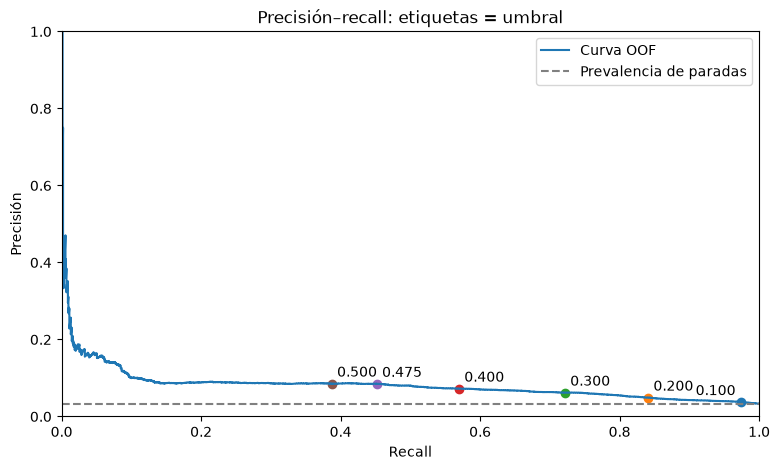

Average precision OOF: 0.08257183403667898


In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score
OUT = Path.cwd() / 'resultados_correcciones'
OUT.mkdir(exist_ok=True)
def guardar_figura(nombre):
    plt.gcf().savefig(OUT / (nombre + '.png'), dpi=150, bbox_inches='tight')
    plt.show()

def bosque_v6():
    return pipeline(RandomForestClassifier(n_estimators=150, max_depth=12,
                    min_samples_leaf=10, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1))
modelo_pit, modelo_comp = bosque_v6(), bosque_v6()
probas_pit_oof = cross_val_predict(modelo_pit, Xpit, ypit, cv=cvpit,
                                  method='predict_proba', n_jobs=1)[:, 1]
UMBRAL_BASE = 0.475
grilla = sorted(set(np.round(np.arange(.025, .501, .025), 3)) | {UMBRAL_BASE})
tabla_umbrales = pd.DataFrame([metricas_umbral(ypit, probas_pit_oof, u) for u in grilla])
elegibles = tabla_umbrales[tabla_umbrales.umbral.le(UMBRAL_BASE)]
UMBRAL_NUEVO = float(elegibles.sort_values(['F2', 'umbral'], ascending=False).iloc[0].umbral)
tabla_umbrales.to_csv(OUT / 'umbrales_oof.csv', index=False)
display(tabla_umbrales.round(4))
print('Umbral F2 elegido exclusivamente en OOF:', UMBRAL_NUEVO)
precision, recall, _ = precision_recall_curve(ypit, probas_pit_oof)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(recall, precision, label='Curva OOF')
comparar = sorted({0.50, UMBRAL_BASE, UMBRAL_NUEVO, 0.10, 0.20, 0.30, 0.40})
for u in comparar:
    m = metricas_umbral(ypit, probas_pit_oof, u)
    ax.scatter(m['recall'], m['precision'])
    ax.annotate(f'{u:.3f}', (m['recall'], m['precision']), xytext=(-4 if m['recall'] > .95 else 4, 5),
                ha='right' if m['recall'] > .95 else 'left', textcoords='offset points')
ax.axhline(ypit.mean(), color='gray', linestyle='--', label='Prevalencia de paradas')
ax.set(xlabel='Recall', ylabel='Precisión', title='Precisión–recall: etiquetas = umbral', xlim=(0, 1), ylim=(0, 1))
ax.legend(); guardar_figura('precision_recall_oof')
print('Average precision OOF:', average_precision_score(ypit, probas_pit_oof))
modelo_pit.fit(Xpit, ypit)
modelo_comp.fit(Xcomp, ycomp)
proba_test = modelo_pit.predict_proba(Xpit_test)[:, 1]


## 2 · Matrices, todas las paradas y todas las falsas alarmas
Se exportan todas las filas, no solo ejemplos. Los conteos usan la población evaluable
de la v6 (vueltas con historia previa), no todas las paradas del CSV bruto.
La normalización por fila mide recuperación de clases; por columna, confiabilidad
de las predicciones. El umbral queda congelado antes de mirar estas tablas de 2025.


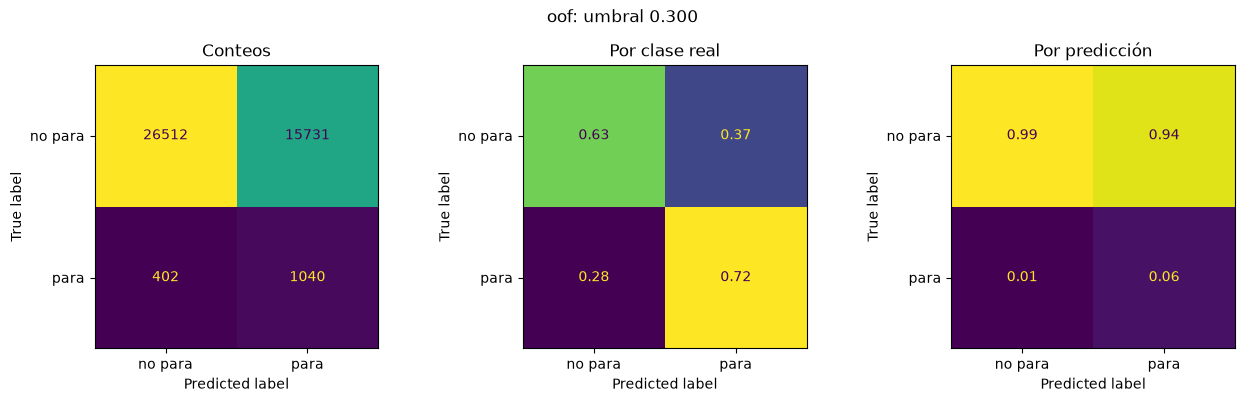

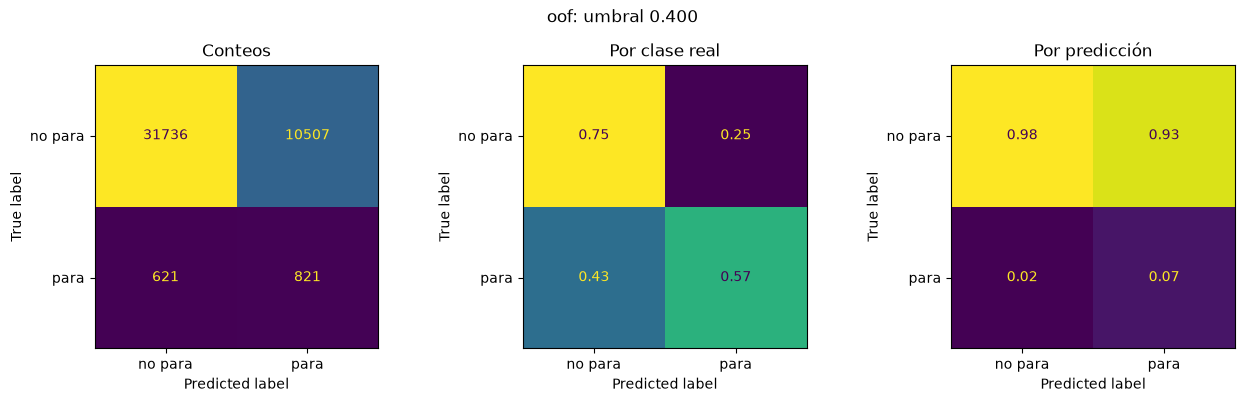

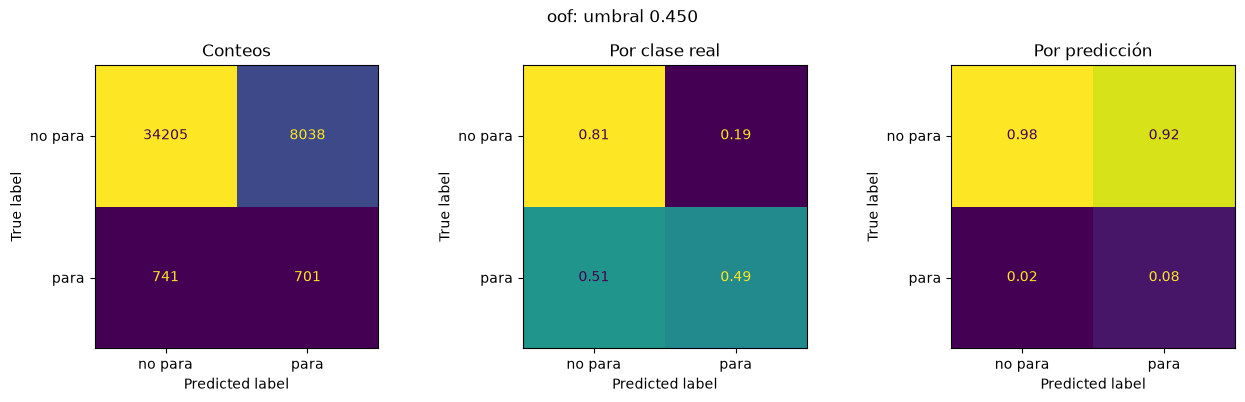

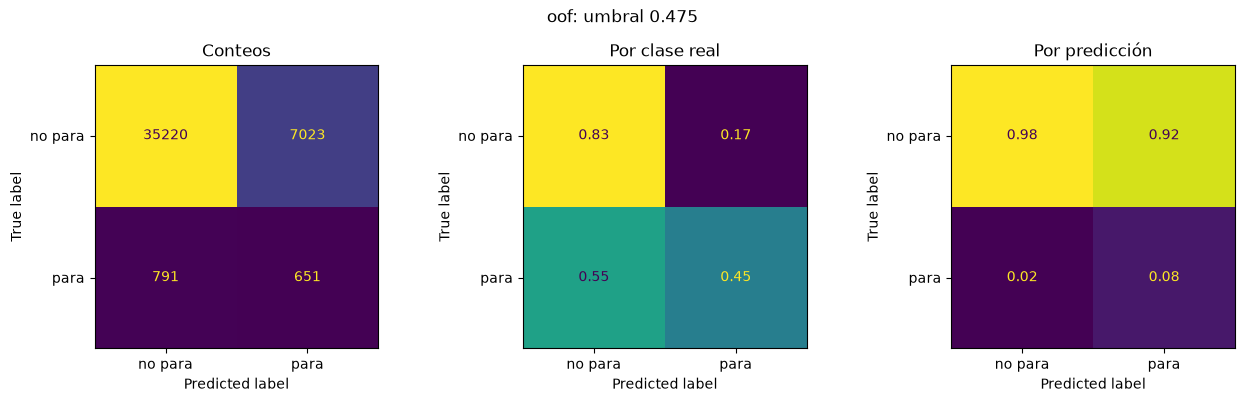

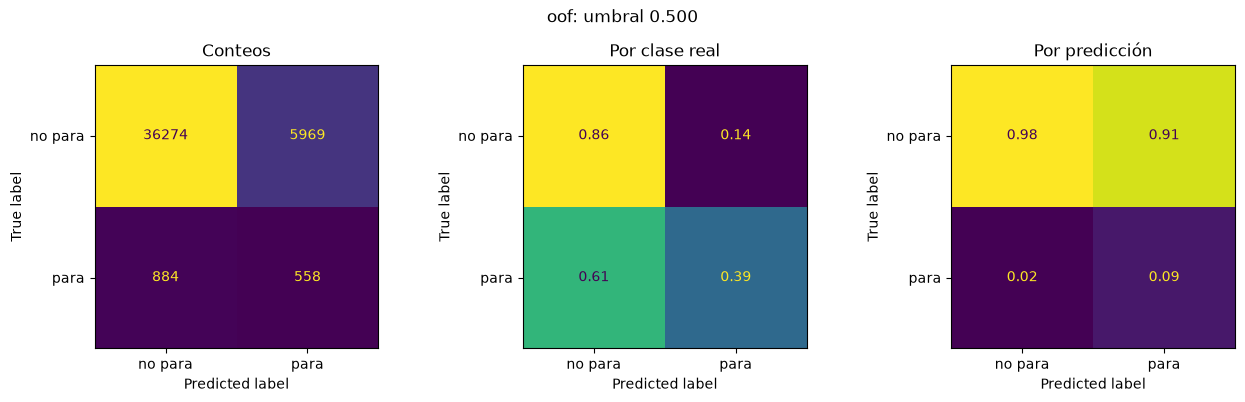

,umbral,VP,FP,FN,VN,precision,recall,F1,F2,alarmas_cada_100_vueltas
0,0.300,1040,15731,402,26512,0.0620,0.7212,0.1142,0.2307,38.3908
1,0.400,821,10507,621,31736,0.0725,0.5693,0.1286,0.2401,25.9311
2,0.450,701,8038,741,34205,0.0802,0.4861,0.1377,0.2416,20.0046
3,0.475,651,7023,791,35220,0.0848,0.4515,0.1428,0.2422,17.5667
4,0.500,558,5969,884,36274,0.0855,0.3870,0.1400,0.2269,14.9411


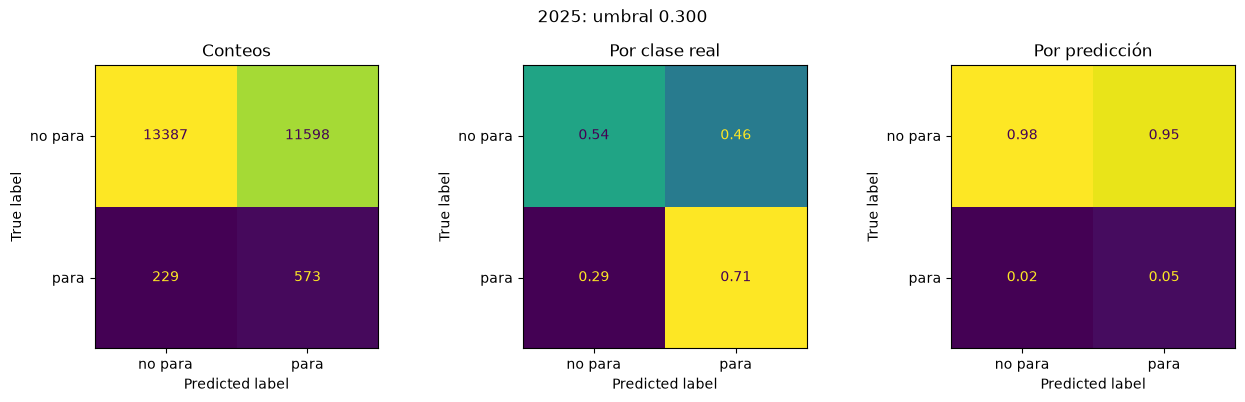

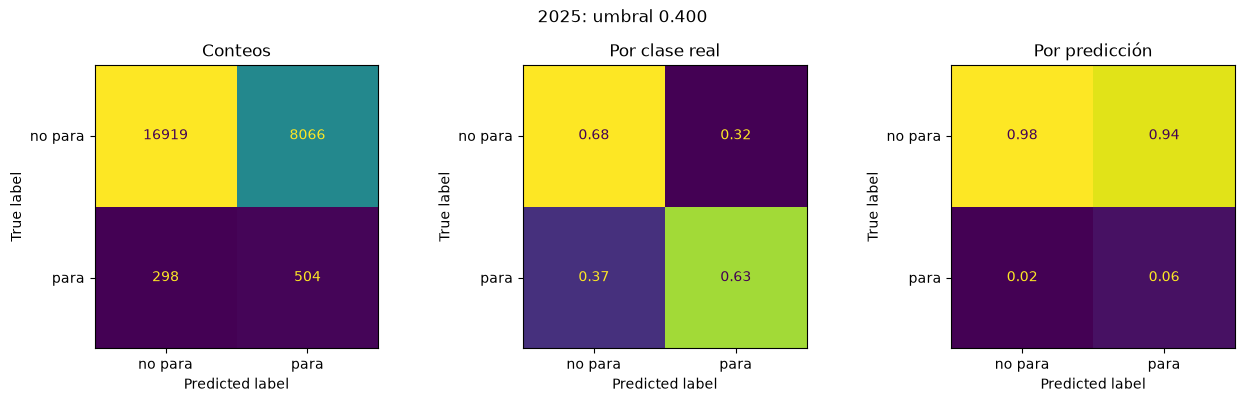

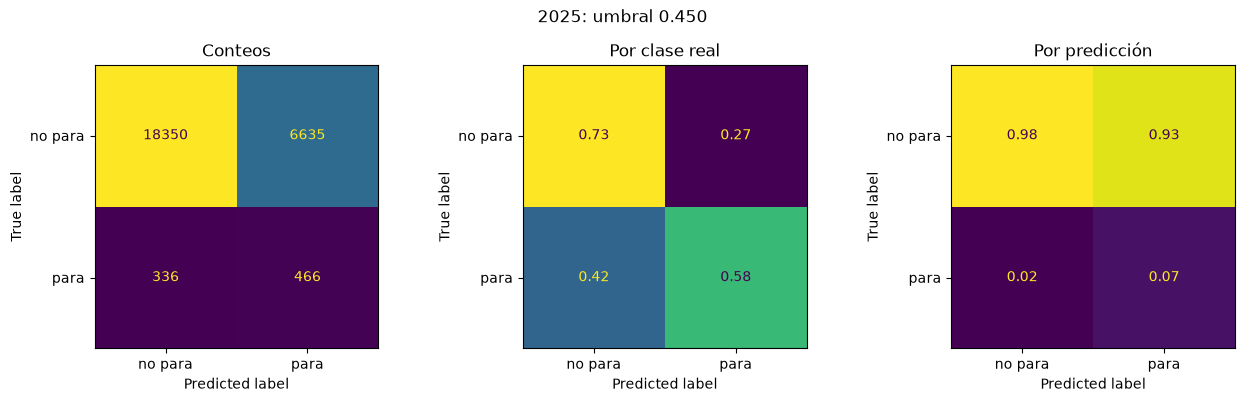

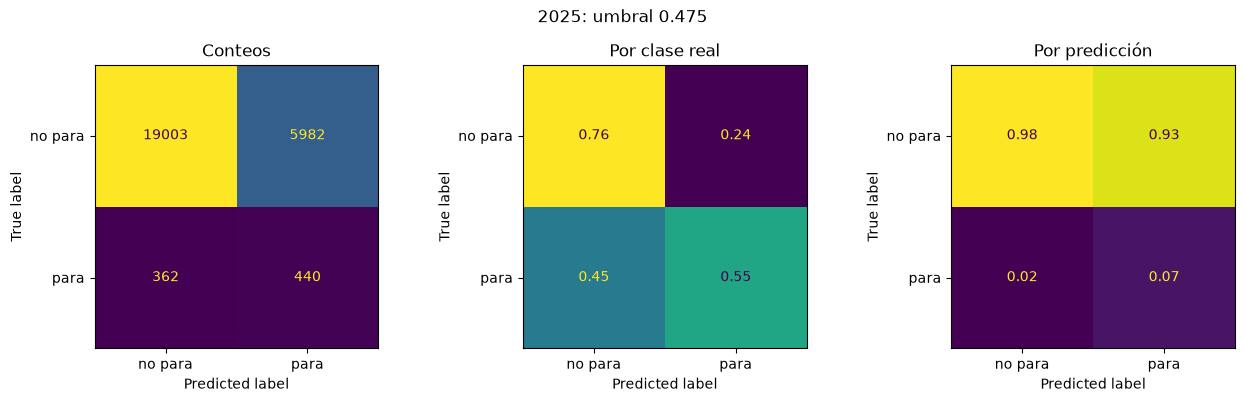

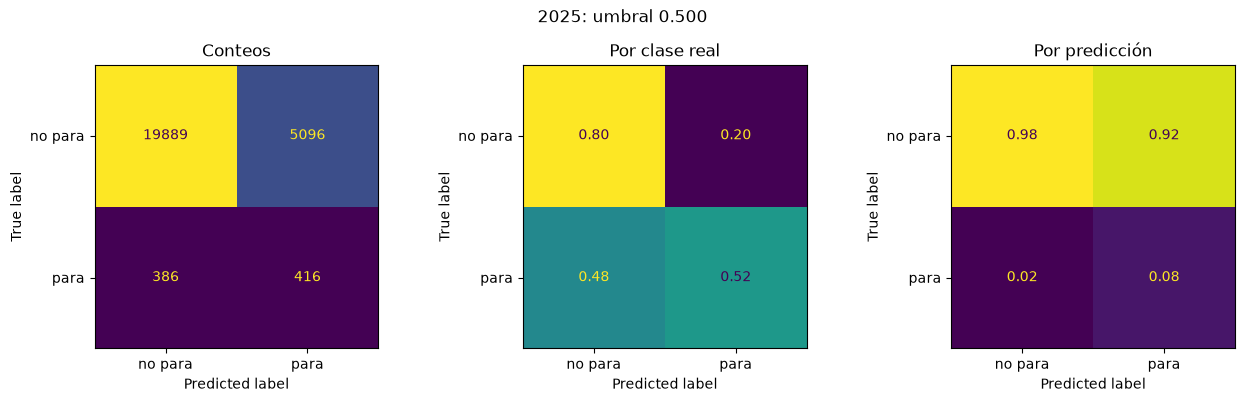

,umbral,VP,FP,FN,VN,precision,recall,F1,F2,alarmas_cada_100_vueltas
0,0.300,573,11598,229,13387,0.0471,0.7145,0.0883,0.1863,47.1982
1,0.400,504,8066,298,16919,0.0588,0.6284,0.1076,0.2140,33.2338
2,0.450,466,6635,336,18350,0.0656,0.5810,0.1179,0.2260,27.5371
3,0.475,440,5982,362,19003,0.0685,0.5486,0.1218,0.2285,24.9040
4,0.500,416,5096,386,19889,0.0755,0.5187,0.1318,0.2385,21.3751


,tolerancia,cobertura_paradas,fraccion_alarmas_cercanas,episodios_emparejados,precision_episodios,recall_episodios,episodios_sin_asociar,conjunto,umbral
0,0,0.7212,0.0620,1040,0.4298,0.7212,1380,oof,0.300
1,1,0.7393,0.1206,1053,0.4351,0.7302,1367,oof,0.300
2,2,0.7503,0.1773,1066,0.4405,0.7393,1354,oof,0.300
3,3,0.7573,0.2321,1075,0.4442,0.7455,1345,oof,0.300
4,0,0.5693,0.0725,821,0.4576,0.5693,973,oof,0.400
5,1,0.5922,0.1413,842,0.4693,0.5839,952,oof,0.400
6,2,0.6012,0.2063,852,0.4749,0.5908,942,oof,0.400
7,3,0.6096,0.2674,862,0.4805,0.5978,932,oof,0.400
8,0,0.4861,0.0802,701,0.4902,0.4861,729,oof,0.450
9,1,0.5090,0.1560,722,0.5049,0.5007,708,oof,0.450


In [11]:
umbrales_comparacion = sorted({0.30, 0.40, 0.45, 0.50, UMBRAL_BASE, UMBRAL_NUEVO})
auditorias, temporales, conteos_fp = {}, [], []
for nombre, datos, p in [('oof', descr[descr.season.lt(2025)].reset_index(drop=True), probas_pit_oof),
                          ('2025', descr[descr.season.eq(2025)].reset_index(drop=True), proba_test)]:
    resumen = []
    for u in umbrales_comparacion:
        t, ep, reales = auditar_alarmas(datos, p, u)
        auditorias[nombre, u] = (t, ep, reales)
        resumen.append(metricas_umbral(t.real, p, u))
        prefijo = f'{nombre}_u{u:.3f}'
        for sufijo, df in [('vueltas', t), ('falsos_positivos', t[t.tipo.eq('FP')]),
                            ('paradas_reales', reales), ('episodios', ep)]:
            df.to_csv(OUT / f'{prefijo}_{sufijo}.csv', index=False)
        temporales.append(resumen_temporal(t, ep, reales).assign(conjunto=nombre, umbral=u))
        conteos_fp.append(t[t.tipo.eq('FP')].categoria_fp.value_counts().rename('FP').reset_index()
                          .assign(conjunto=nombre, umbral=u))
        fig, axs = plt.subplots(1, 3, figsize=(13, 4))
        for ax, norm, titulo in zip(axs, [None, 'true', 'pred'], ['Conteos', 'Por clase real', 'Por predicción']):
            ConfusionMatrixDisplay.from_predictions(t.real, t.alarma, labels=[False, True],
                display_labels=['no para', 'para'], normalize=norm,
                values_format='d' if norm is None else '.2f', ax=ax, colorbar=False)
            ax.set_title(titulo)
        fig.suptitle(f'{nombre}: umbral {u:.3f}')
        fig.tight_layout(); guardar_figura(prefijo + '_matrices')
    display(pd.DataFrame(resumen).round(4))
    pd.DataFrame(resumen).to_csv(OUT / f'{nombre}_comparacion.csv', index=False)
temporal = pd.concat(temporales, ignore_index=True)
fp_categorias = pd.concat(conteos_fp, ignore_index=True)
temporal.to_csv(OUT / 'metricas_temporales.csv', index=False)
fp_categorias.to_csv(OUT / 'categorias_fp.csv', index=False)
display(temporal.round(4))


## 3 · Distancia y episodios: métricas complementarias
Un FP exacto sigue siendo FP aunque haya una parada después. La fracción de alarmas
cercanas NO es la precisión exacta. Cobertura cuenta cada parada una sola vez.
Para precisión/recall por episodios se empareja cada episodio con una sola parada y
cada parada con un solo episodio. Una parada interrumpe la racha. Se permite coincidencia
en la vuelta real o en las k anteriores, nunca una alarma posterior.

La distancia usa la próxima parada, no la parada más cercana en ambas direcciones.
Sin parada posterior observada se reporta por separado: puede ser el stint final,
un retiro o un final de observación. No se imputa una distancia ni una intención del piloto.


categoria_fp,1 vuelta,2–3 vueltas,4–10 vueltas,>10 vueltas,sin parada posterior observada
umbral,,,,,
0.300,982,1870,4845,3936,4098
0.400,780,1428,3449,2355,2495
0.450,662,1184,2612,1818,1762
0.475,599,1058,2296,1586,1484
0.500,512,914,1952,1382,1209


categoria_fp,1 vuelta,2–3 vueltas,4–10 vueltas,>10 vueltas,sin parada posterior observada
umbral,,,,,
0.300,0.062,0.119,0.308,0.250,0.261
0.400,0.074,0.136,0.328,0.224,0.237
0.450,0.082,0.147,0.325,0.226,0.219
0.475,0.085,0.151,0.327,0.226,0.211
0.500,0.086,0.153,0.327,0.232,0.203


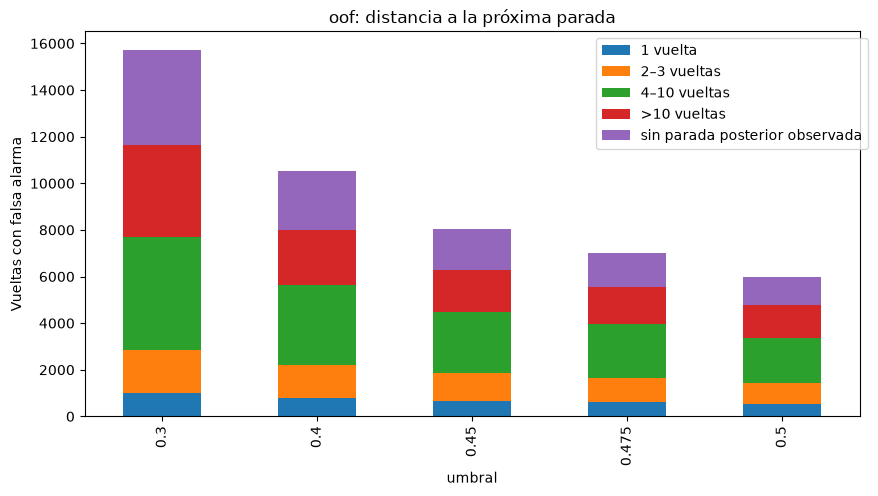

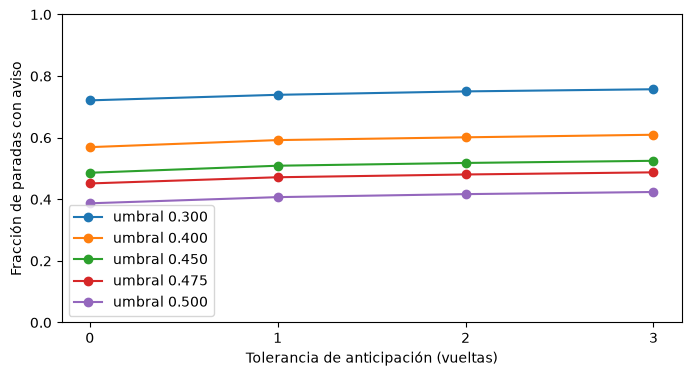

,umbral,FP,FP_con_parada_posterior,distancia_mediana,distancia_p90,FP_sin_parada_posterior,FP_sin_parada_y_menos_3_vueltas_observadas,episodios,duracion_mediana,duracion_p90
0,0.300,15731,11633,7.0,19.0,4098,412,2420,3.0,19.0
1,0.400,10507,8012,7.0,18.0,2495,174,1794,3.0,17.0
2,0.450,8038,6276,6.0,18.0,1762,67,1430,3.0,16.0
3,0.475,7023,5539,6.0,18.0,1484,36,1281,3.0,16.0
4,0.500,5969,4760,6.0,18.0,1209,22,1116,3.0,15.0


categoria_fp,1 vuelta,2–3 vueltas,4–10 vueltas,>10 vueltas,sin parada posterior observada
umbral,,,,,
0.300,568,1071,3199,3442,3318
0.400,495,956,2669,2307,1639
0.450,446,858,2307,1794,1230
0.475,427,811,2093,1566,1085
0.500,396,748,1755,1305,892


categoria_fp,1 vuelta,2–3 vueltas,4–10 vueltas,>10 vueltas,sin parada posterior observada
umbral,,,,,
0.300,0.049,0.092,0.276,0.297,0.286
0.400,0.061,0.119,0.331,0.286,0.203
0.450,0.067,0.129,0.348,0.270,0.185
0.475,0.071,0.136,0.350,0.262,0.181
0.500,0.078,0.147,0.344,0.256,0.175


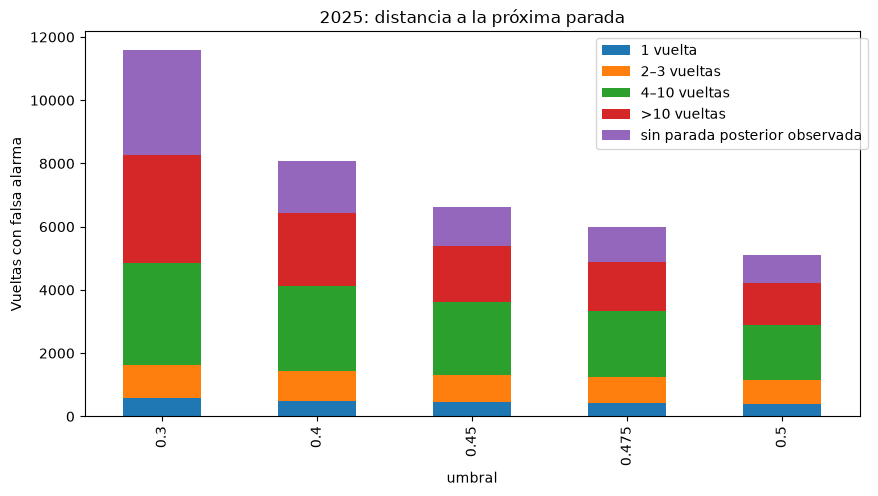

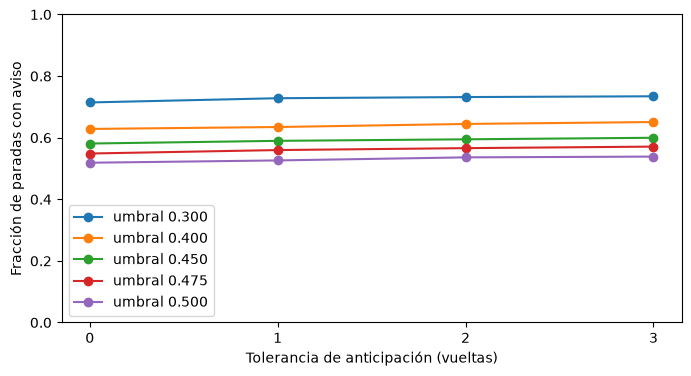

,umbral,FP,FP_con_parada_posterior,distancia_mediana,distancia_p90,FP_sin_parada_posterior,FP_sin_parada_y_menos_3_vueltas_observadas,episodios,duracion_mediana,duracion_p90
0,0.300,11598,8280,9.0,22.0,3318,347,1415,4.0,23.0
1,0.400,8066,6427,8.0,20.0,1639,92,1174,3.0,19.7
2,0.450,6635,5405,7.0,19.0,1230,69,983,4.0,19.0
3,0.475,5982,4897,7.0,19.0,1085,66,936,4.0,18.0
4,0.500,5096,4204,7.0,19.0,892,59,893,4.0,16.0


In [12]:
orden_fp = ['1 vuelta', '2–3 vueltas', '4–10 vueltas', '>10 vueltas', 'sin parada posterior observada']
for nombre in ['oof', '2025']:
    cats = fp_categorias[fp_categorias.conjunto.eq(nombre)].pivot(index='umbral', columns='categoria_fp', values='FP').reindex(columns=orden_fp).fillna(0)
    display(cats)
    display(cats.div(cats.sum(axis=1).replace(0, np.nan), axis=0).round(3))
    cats.plot.bar(stacked=True, figsize=(10, 5))
    plt.ylabel('Vueltas con falsa alarma'); plt.title(f'{nombre}: distancia a la próxima parada')
    plt.legend(bbox_to_anchor=(1.02, 1)); guardar_figura(nombre + '_distancias_fp')
    fig, ax = plt.subplots(figsize=(8, 4))
    for u in umbrales_comparacion:
        r = temporal[temporal.conjunto.eq(nombre) & temporal.umbral.eq(u)]
        ax.plot(r.tolerancia, r.cobertura_paradas, marker='o', label=f'umbral {u:.3f}')
    ax.set(xlabel='Tolerancia de anticipación (vueltas)', ylabel='Fracción de paradas con aviso', xticks=range(4), ylim=(0, 1))
    ax.legend(); guardar_figura(nombre + '_cobertura')
    filas = []
    for u in umbrales_comparacion:
        t, ep, reales = auditorias[nombre, u]
        fp = t[t.tipo.eq('FP')]
        d = fp.distancia_proxima_parada.dropna()
        filas.append({'umbral': u, 'FP': len(fp), 'FP_con_parada_posterior': len(d),
                      'distancia_mediana': d.median(), 'distancia_p90': d.quantile(.9),
                      'FP_sin_parada_posterior': fp.distancia_proxima_parada.isna().sum(),
                      'FP_sin_parada_y_menos_3_vueltas_observadas': (fp.distancia_proxima_parada.isna() & fp.vueltas_observadas_restantes.lt(3)).sum(),
                      'episodios': len(ep), 'duracion_mediana': ep.duracion.median(), 'duracion_p90': ep.duracion.quantile(.9)})
    display(pd.DataFrame(filas).round(3))
    pd.DataFrame(filas).to_csv(OUT / f'{nombre}_distancias_episodios.csv', index=False)


## 4 · Casos verificables y límites de interpretación
Se selecciona determinísticamente un caso por categoría (máximo puntaje, desempate
por carrera/piloto/vuelta). Son ejemplos descriptivos, no prueba de estrategia óptima.
En cada caso se muestra la trayectoria completa para no ocultar alarmas persistentes.
Safety car se conserva solo para descripción, tal como en la v6.


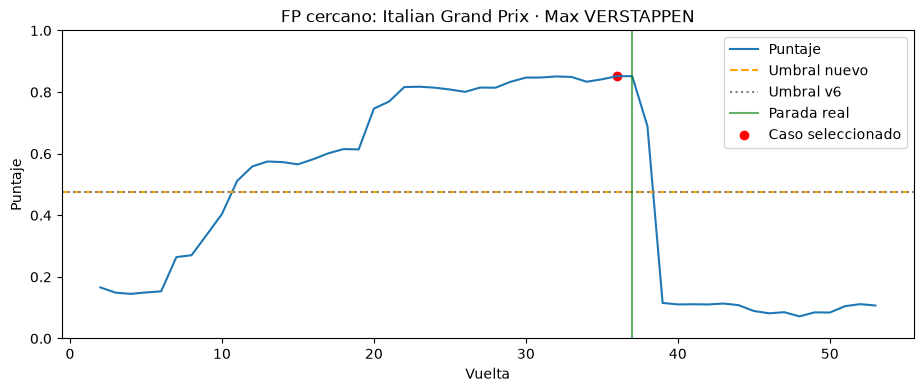

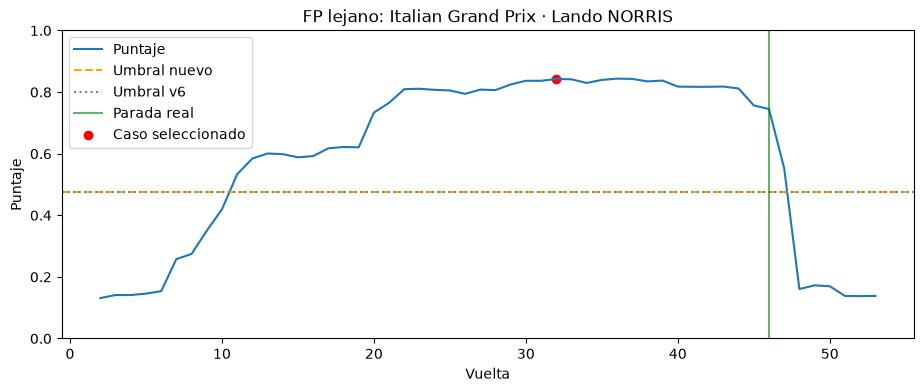

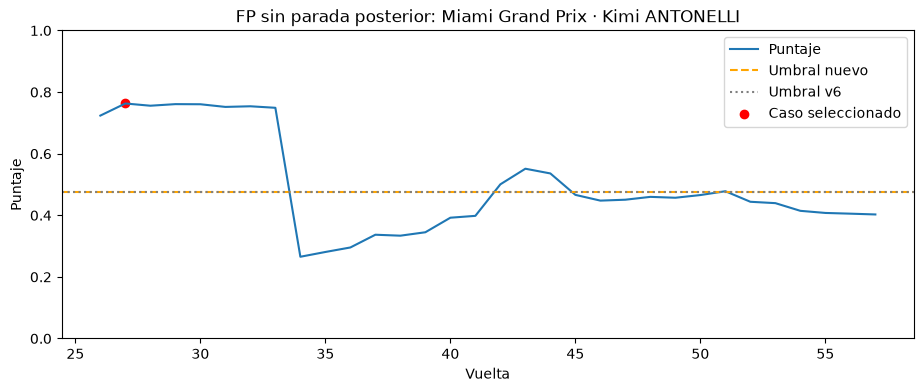

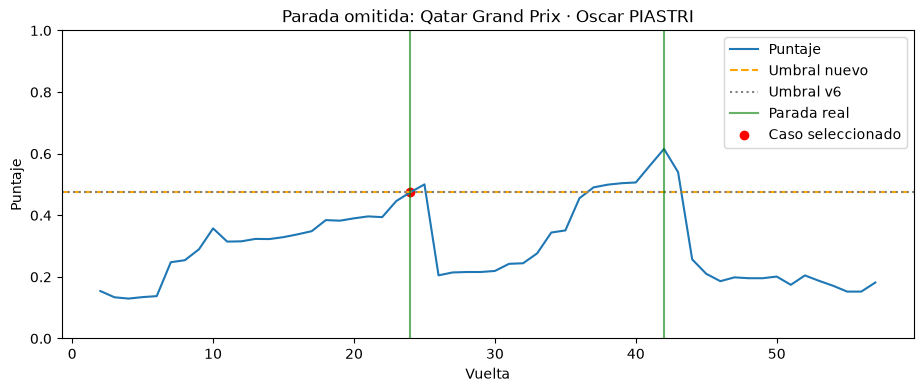

,caso,meeting_name,full_name,lap_number,puntaje,distancia_proxima_parada,tyre_age_prev,compound_prev,safety_car_active
0,FP cercano,Italian Grand Prix,Max VERSTAPPEN,36,0.851769,1.0,34.0,MEDIUM,False
1,FP lejano,Italian Grand Prix,Lando NORRIS,32,0.842485,14.0,30.0,MEDIUM,False
2,FP sin parada posterior,Miami Grand Prix,Kimi ANTONELLI,27,0.763010,NaN,49.0,MEDIUM,False
3,Parada omitida,Qatar Grand Prix,Oscar PIASTRI,24,0.474874,18.0,22.0,MEDIUM,False


,paradas,edad_mediana,fraccion_lluvia,fraccion_safety_car
tipo,,,,
FN,362,11.0,0.229282,0.281768
VP,440,22.0,0.006818,0.009091


In [13]:
t, ep, reales = auditorias['2025', UMBRAL_NUEVO]
casos = []
for etiqueta, mascara in [('FP cercano', t.tipo.eq('FP') & t.distancia_proxima_parada.between(1, 3)),
                          ('FP lejano', t.tipo.eq('FP') & t.distancia_proxima_parada.gt(10)),
                          ('FP sin parada posterior', t.tipo.eq('FP') & t.distancia_proxima_parada.isna()),
                          ('Parada omitida', t.tipo.eq('FN'))]:
    candidatos = t[mascara].sort_values(['puntaje'] + CLAVE, ascending=[False, True, True, True])
    if candidatos.empty:
        print(etiqueta, ': no hay casos'); continue
    r = candidatos.iloc[0]
    casos.append(r.to_dict() | {'caso': etiqueta})
    g = t[t.session_key.eq(r.session_key) & t.driver_number.eq(r.driver_number)].sort_values('lap_number')
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(g.lap_number, g.puntaje, label='Puntaje')
    ax.axhline(UMBRAL_NUEVO, color='orange', linestyle='--', label='Umbral nuevo')
    ax.axhline(UMBRAL_BASE, color='gray', linestyle=':', label='Umbral v6')
    for j, lap in enumerate(g.loc[g.real, 'lap_number']):
        ax.axvline(lap, color='green', alpha=.6, label='Parada real' if j == 0 else None)
    ax.scatter([r.lap_number], [r.puntaje], color='red', label='Caso seleccionado')
    ax.set(xlabel='Vuelta', ylabel='Puntaje', title=f'{etiqueta}: {r.meeting_name} · {r.full_name}', ylim=(0, 1))
    ax.legend(); guardar_figura('caso_' + str(len(casos)))
casos = pd.DataFrame(casos)
casos.to_csv(OUT / 'casos.csv', index=False)
display(casos[['caso', 'meeting_name', 'full_name', 'lap_number', 'puntaje', 'distancia_proxima_parada', 'tyre_age_prev', 'compound_prev', 'safety_car_active']])
perfil = t[t.real].groupby('tipo').agg(paradas=('real', 'size'),
    edad_mediana=('tyre_age_prev', 'median'),
    fraccion_lluvia=('objetivo_compuesto', lambda x: x.eq('LLUVIA').mean()),
    fraccion_safety_car=('safety_car_active', lambda x: x.astype(str).str.lower().eq('true').mean()))
display(perfil); perfil.to_csv(OUT / 'perfil_paradas_detectadas_omitidas.csv')


## 5 · Qué variables aportan a cada random forest
Permutación sobre variables construidas en el fold de validación. Para parada se mide
F1 y F2 con el umbral nuevo, además de F1 con el umbral v6; para compuesto, F1 macro.
La caída puede ser negativa por ruido o redundancia: no prueba que una variable sea
inútil ni que el modelo no la use. Se informan todos los atributos y su variabilidad.
Los atributos excluidos tampoco son atributos que el bosque haya aprendido a ignorar.


,modelo,metrica,variable,caida_media,desvio,folds_positivos
8,compuesto,F1_macro,lap_number,0.0586,0.0486,4
4,compuesto,F1_macro,field_lluvia_prev,0.0533,0.0506,3
3,compuesto,F1_macro,field_hard_prev,0.0460,0.0182,4
6,compuesto,F1_macro,field_soft_prev,0.0420,0.0313,3
11,compuesto,F1_macro,stops_before,0.0286,0.0249,4
15,compuesto,F1_macro,used_hard,0.0218,0.0253,3
16,compuesto,F1_macro,used_medium,0.0193,0.0036,4
0,compuesto,F1_macro,air_temperature_prev,0.0188,0.0148,3
2,compuesto,F1_macro,compound_prev,0.0147,0.0106,4
17,compuesto,F1_macro,used_soft,0.0097,0.0179,3


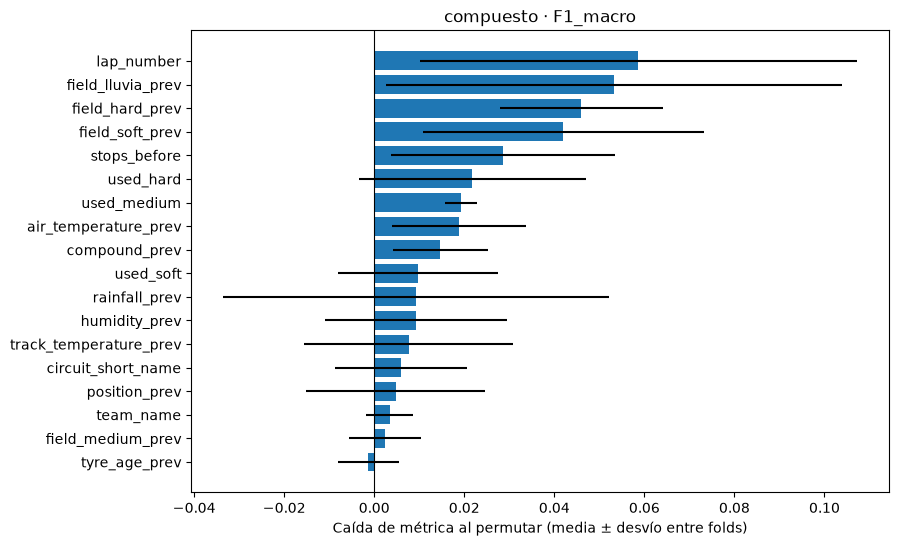

,modelo,metrica,variable,caida_media,desvio,folds_positivos
32,parada,F1_umbral_nuevo,tyre_age_prev,0.0353,0.0122,4
33,parada,F1_umbral_nuevo,used_hard,0.0182,0.0075,4
29,parada,F1_umbral_nuevo,stops_before,0.0153,0.0129,4
20,parada,F1_umbral_nuevo,compound_prev,0.0128,0.0059,4
26,parada,F1_umbral_nuevo,lap_number,0.0089,0.0040,4
19,parada,F1_umbral_nuevo,circuit_short_name,0.0071,0.0047,4
18,parada,F1_umbral_nuevo,air_temperature_prev,0.0042,0.0089,2
27,parada,F1_umbral_nuevo,position_prev,0.0036,0.0032,3
25,parada,F1_umbral_nuevo,humidity_prev,0.0031,0.0061,3
24,parada,F1_umbral_nuevo,field_soft_prev,0.0030,0.0046,3


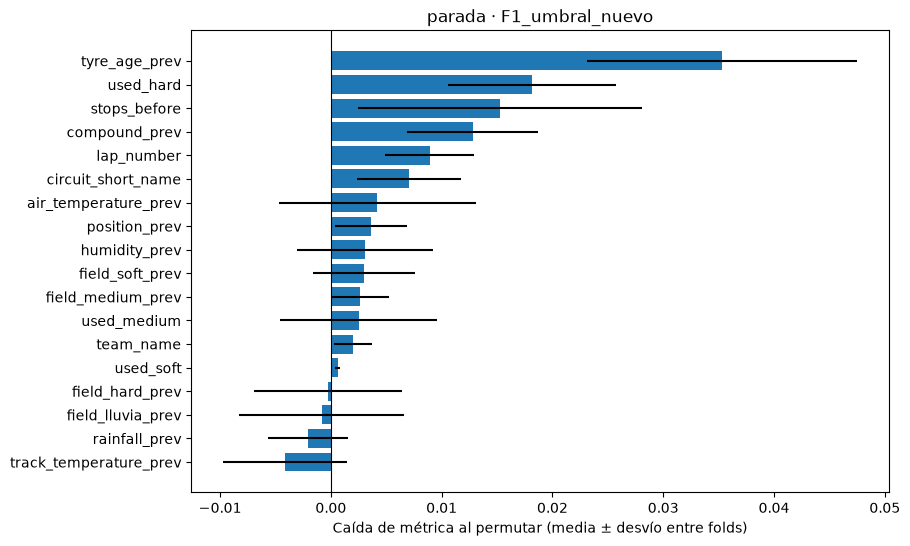

,modelo,metrica,variable,caida_media,desvio,folds_positivos
50,parada,F1_umbral_v6,tyre_age_prev,0.0353,0.0122,4
51,parada,F1_umbral_v6,used_hard,0.0182,0.0075,4
47,parada,F1_umbral_v6,stops_before,0.0153,0.0129,4
38,parada,F1_umbral_v6,compound_prev,0.0128,0.0059,4
44,parada,F1_umbral_v6,lap_number,0.0089,0.0040,4
37,parada,F1_umbral_v6,circuit_short_name,0.0071,0.0047,4
36,parada,F1_umbral_v6,air_temperature_prev,0.0042,0.0089,2
45,parada,F1_umbral_v6,position_prev,0.0036,0.0032,3
43,parada,F1_umbral_v6,humidity_prev,0.0031,0.0061,3
42,parada,F1_umbral_v6,field_soft_prev,0.0030,0.0046,3


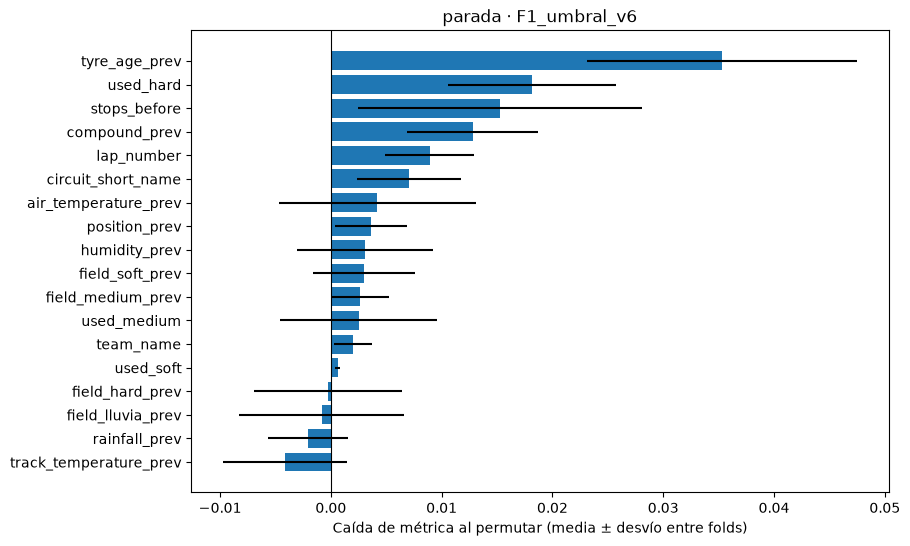

,modelo,metrica,variable,caida_media,desvio,folds_positivos
68,parada,F2_umbral_nuevo,tyre_age_prev,0.0666,0.0169,4
69,parada,F2_umbral_nuevo,used_hard,0.0450,0.0169,4
56,parada,F2_umbral_nuevo,compound_prev,0.0403,0.0178,4
65,parada,F2_umbral_nuevo,stops_before,0.0398,0.0255,4
62,parada,F2_umbral_nuevo,lap_number,0.0328,0.0081,4
54,parada,F2_umbral_nuevo,air_temperature_prev,0.0116,0.0186,2
55,parada,F2_umbral_nuevo,circuit_short_name,0.0108,0.0070,4
60,parada,F2_umbral_nuevo,field_soft_prev,0.0098,0.0076,4
57,parada,F2_umbral_nuevo,field_hard_prev,0.0084,0.0085,3
70,parada,F2_umbral_nuevo,used_medium,0.0078,0.0091,4


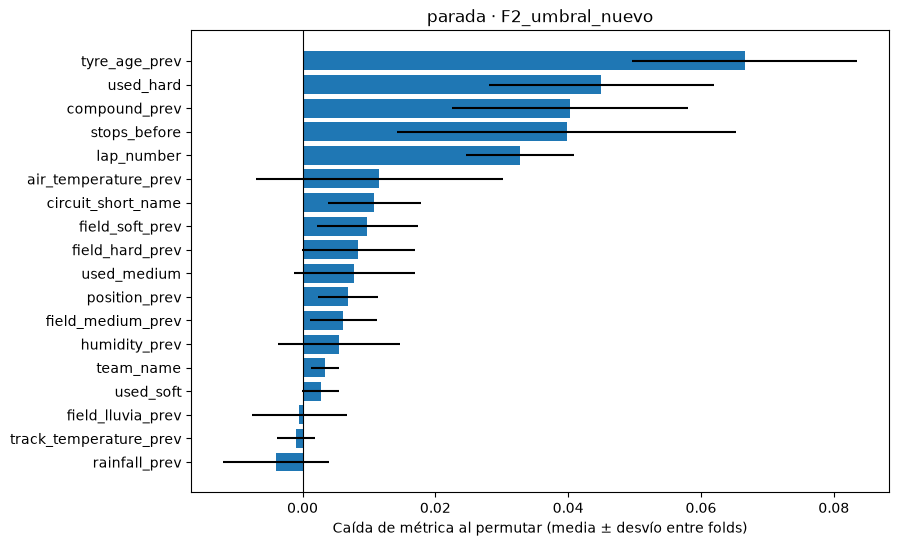

Excluidas por diseño, no ignoradas por el bosque: ['current_compound', 'gap_to_leader_raw', 'interval_raw', 'lane_duration', 'lap_duration', 'new_compound', 'pit_duration', 'pit_stop', 'safety_car_active', 'session_max_lap_observed', 'stint_number', 'stop_duration', 'yellow_flag_active']


In [14]:
def score_umbral(umbral, beta):
    def puntuar(est, X, y):
        pred = est.predict_proba(X)[:, list(est.classes_).index(1)] >= umbral
        return fbeta_score(y, pred, beta=beta, zero_division=0)
    return puntuar

importancias = []
for nombre, modelo, X, y, cv in [('parada', modelo_pit, Xpit, ypit, cvpit),
                                  ('compuesto', modelo_comp, Xcomp, ycomp, cvcomp)]:
    scores = {'F1_umbral_v6': score_umbral(UMBRAL_BASE, 1),
              'F1_umbral_nuevo': score_umbral(UMBRAL_NUEVO, 1),
              'F2_umbral_nuevo': score_umbral(UMBRAL_NUEVO, 2)} if nombre == 'parada' else {'F1_macro': 'f1_macro'}
    for fold, (tr, va) in enumerate(cv.split(), 1):
        est = clone(modelo).fit(X.iloc[tr], y.iloc[tr])
        Xva = est.named_steps['historia'].transform(X.iloc[va])
        resultado = permutation_importance(est[1:], Xva, y.iloc[va], scoring=scores,
                                          n_repeats=3, random_state=SEED, n_jobs=1)
        for metrica, valor in resultado.items():
            importancias.append(pd.DataFrame({'variable': FEATURES, 'caida': valor.importances_mean,
                                              'modelo': nombre, 'metrica': metrica, 'fold': fold}))
importancias = pd.concat(importancias, ignore_index=True)
importancias.to_csv(OUT / 'importancias_por_fold.csv', index=False)
imp = importancias.groupby(['modelo', 'metrica', 'variable']).agg(
    caida_media=('caida', 'mean'), desvio=('caida', 'std'), folds_positivos=('caida', lambda x: (x > 0).sum())).reset_index()
imp.to_csv(OUT / 'importancias_resumen.csv', index=False)
for (modelo, metrica), g in imp.groupby(['modelo', 'metrica']):
    g = g.sort_values('caida_media')
    display(g.sort_values('caida_media', ascending=False).round(4))
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(g.variable, g.caida_media, xerr=g.desvio)
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(xlabel='Caída de métrica al permutar (media ± desvío entre folds)', title=f'{modelo} · {metrica}')
    guardar_figura(f'importancia_{modelo}_{metrica}')
print('Excluidas por diseño, no ignoradas por el bosque:', sorted(PROHIBIDAS))


## 6 · Conclusión generada a partir de esta corrida
Las nuevas métricas describen la cercanía a la decisión observada. No permiten
determinar si una parada alternativa habría sido mejor ni atribuir intenciones al piloto.
Para demostrar una mejora de generalización hace falta una evaluación independiente.


In [15]:
a = metricas_umbral(ypit_test, proba_test, UMBRAL_BASE)
b = metricas_umbral(ypit_test, proba_test, UMBRAL_NUEVO)
r = temporal[temporal.conjunto.eq('2025') & temporal.umbral.eq(UMBRAL_NUEVO)].set_index('tolerancia')
display(Markdown(f"""**Comparación descriptiva 2025.** Umbral {UMBRAL_BASE:.3f} → {UMBRAL_NUEVO:.3f}:
recall {a['recall']:.1%} → {b['recall']:.1%}; precisión {a['precision']:.1%} → {b['precision']:.1%};
FP {a['FP']} → {b['FP']}; FN {a['FN']} → {b['FN']}.

Con el nuevo umbral, cobertura exacta {r.loc[0, 'cobertura_paradas']:.1%}; con anticipación de hasta
3 vueltas {r.loc[3, 'cobertura_paradas']:.1%}. La precisión por episodios con esa tolerancia es
{r.loc[3, 'precision_episodios']:.1%}. No es intercambiable con la precisión por vuelta.
"""))
versiones = {'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'umbral_base': UMBRAL_BASE, 'umbral_nuevo': UMBRAL_NUEVO, 'regla': 'maximo F2 OOF; empate mayor umbral; candidatos <= 0.475'}
(OUT / 'ejecucion.json').write_text(json.dumps(versiones, indent=2), encoding='utf-8')
print('Tablas y figuras:', OUT.resolve())


**Comparación descriptiva 2025.** Umbral 0.475 → 0.475:
recall 54.9% → 54.9%; precisión 6.9% → 6.9%;
FP 5982 → 5982; FN 362 → 362.

Con el nuevo umbral, cobertura exacta 54.9%; con anticipación de hasta
3 vueltas 57.1%. La precisión por episodios con esa tolerancia es
48.9%. No es intercambiable con la precisión por vuelta.


Tablas y figuras: C:\Users\SergioFarias\Downloads\UTN FRM\Ciencia de datos 2026\f1-strategy-pipeline\Entrega3\resultados_correcciones
